<a href="https://colab.research.google.com/github/Dewanggieee/Analisis-Pola-Penyebaran-COVID-19-di-Indonesia-Menggunakan-Moran-s-I-dan-Spatial-Clustering/blob/main/Kelompok_4_Project_Data_Warehouse.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# World Bank Economic Indicators  
## Atoti OLAP, Cube, Query, Dashboard & Visualisasi

---
## STEP 0 – Install & Import

In [ ]:
!pip install sqlalchemy psycopg2-binary atoti pandas numpy matplotlib --quiet


[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings('ignore')

from sqlalchemy import create_engine, text
from urllib.parse import quote_plus

print('Semua library berhasil diimport')

Semua library berhasil diimport


---
## STEP 1 – Load Data & Bangun Star Schema

In [ ]:
# Load data hasil cleaning
df = pd.read_csv('Data/data_cleaning.csv')
df['extracted_at'] = pd.to_datetime(df['extracted_at'])
df['year'] = df['year'].astype(int)

print(f'   Data dimuat: {df.shape[0]:,} baris x {df.shape[1]} kolom')
print(f'   Tahun    : {df["year"].min()} – {df["year"].max()}')
print(f'   Negara   : {df["country_id"].nunique()} negara')
print(f'   Indikator: {df["indicator_name"].nunique()} indikator')
print(f'   Batch    : {sorted(df["batch"].unique())}')
df.head(3)

   Data dimuat: 13,671 baris x 13 kolom
   Tahun    : 2015 – 2023
   Negara   : 217 negara
   Indikator: 7 indikator
   Batch    : ['batch_1', 'batch_2', 'batch_3']


,country_id,country_name,indicator_code,indicator_name,year,value,batch,extracted_at,country_ID3,region_id,region_name,income_group,decade
0,AFG,Afghanistan,NY.GDP.MKTP.CD,GDP (current US$),2017,1.875346e+10,batch_1,2026-05-28 18:00:19.619025,AFG,MEA,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2010s
1,AFG,Afghanistan,NY.GDP.MKTP.CD,GDP (current US$),2016,1.811657e+10,batch_1,2026-05-28 18:00:19.619025,AFG,MEA,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2010s
2,AFG,Afghanistan,NY.GDP.MKTP.CD,GDP (current US$),2015,1.913422e+10,batch_1,2026-05-28 18:00:19.619025,AFG,MEA,"Middle East, North Africa, Afghanistan & Pakistan",Low income,2010s


Pada tahap ini dilakukan proses pemuatan data hasil cleaning ke dalam sistem Data Warehouse. Dataset yang digunakan berisi 13.671 observasi indikator ekonomi makro global dari 217 negara selama periode 2015–2023. Pembagian data ke dalam tiga batch dilakukan untuk mensimulasikan proses ETL secara bertahap seperti yang umum diterapkan pada lingkungan data warehouse nyata.

Jumlah data yang cukup besar dan cakupan negara yang luas menunjukkan bahwa data yang digunakan telah memenuhi kebutuhan analisis ekonomi makro global.

In [ ]:
# TABEL STAR SCHEMA

# dim_time
dim_time = (
    df[['year', 'decade']].drop_duplicates()
    .sort_values('year').reset_index(drop=True)
)
dim_time.insert(0, 'time_id', range(1, len(dim_time) + 1))

# dim_country
dim_country = (
    df[['country_id', 'country_name', 'region_id', 'region_name', 'income_group']]
    .drop_duplicates(subset='country_id')
    .sort_values('country_id').reset_index(drop=True)
)
dim_country.insert(0, 'country_sk', range(1, len(dim_country) + 1))

# dim_indicator
dim_indicator = (
    df[['indicator_code', 'indicator_name']].drop_duplicates()
    .sort_values('indicator_code').reset_index(drop=True)
)
dim_indicator.insert(0, 'indicator_id', range(1, len(dim_indicator) + 1))

# fact_economy – join surrogate keys
fact = (
    df[['country_id', 'indicator_code', 'year', 'value', 'batch', 'extracted_at']]
    .merge(dim_country[['country_sk', 'country_id']], on='country_id', how='left')
    .merge(dim_indicator[['indicator_id', 'indicator_code']], on='indicator_code', how='left')
    .merge(dim_time[['time_id', 'year']], on='year', how='left')
)
fact_economy = fact[['country_sk', 'indicator_id', 'time_id', 'value', 'batch', 'extracted_at']].copy()

print(f'dim_time      : {len(dim_time)} baris')
print(f'dim_country   : {len(dim_country)} baris')
print(f'dim_indicator : {len(dim_indicator)} baris')
print(f'fact_economy  : {len(fact_economy):,} baris')
print('\n Star Schema selesai dibangun')

dim_time      : 9 baris
dim_country   : 217 baris
dim_indicator : 7 baris
fact_economy  : 13,671 baris

 Star Schema selesai dibangun


Data warehouse dirancang menggunakan pendekatan Star Schema yang terdiri dari satu tabel fakta dan tiga tabel dimensi. Tabel fact_economy berfungsi sebagai pusat penyimpanan data numerik indikator ekonomi, sedangkan tabel dimensi digunakan untuk menyimpan informasi pendukung berupa waktu, negara, dan indikator ekonomi.

Struktur star schema dipilih karena mampu meningkatkan efisiensi query analitis serta mempermudah proses agregasi data dalam kegiatan OLAP (Online Analytical Processing).

---
## STEP 2 – Koneksi ke Supabase PostgreSQL

In [ ]:
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus


# Pisahkan komponen koneksi
DB_USER     = "postgres.lmtosdujmeytlfybinab"
DB_PASSWORD = quote_plus("Astridregita408")   # encode karakter spesial otomatis
DB_HOST     = "aws-1-ap-south-1.pooler.supabase.com"
DB_PORT     = "5432"
DB_NAME     = "postgres"

CONNECTION_STRING = f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"

# Engine 1: Direct connection (port 5432) → untuk DDL
engine_direct = create_engine(
    f'postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:5432/{DB_NAME}',
    echo=False,
    connect_args={'connect_timeout': 10,
                  'options': '-c statement_timeout=60000'}
)

# Engine 2: Pooler (port 6543) → untuk INSERT data
engine_pool = create_engine(
    f'postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:6543/{DB_NAME}',
    echo=False,
    connect_args={'connect_timeout': 10}
)

# Test koneksi direct
try:
    with engine_direct.connect() as conn:
        ver = conn.execute(text('SELECT version();')).fetchone()[0]
        print(' engine_direct (port 5432) OK')
        print('  ', ver[:60])
except Exception as e:
    print(' engine_direct gagal:', str(e)[:100])

# Test koneksi pooler
try:
    with engine_pool.connect() as conn:
        conn.execute(text('SELECT 1;'))
        print(' engine_pool   (port 6543) OK')
except Exception as e:
    print(' engine_pool gagal:', str(e)[:100])

 engine_direct (port 5432) OK
   PostgreSQL 17.6 on aarch64-unknown-linux-gnu, compiled by gc
 engine_pool   (port 6543) OK


---
## STEP 3 – Enable Extensions

In [ ]:
# Jalankan SATU PER SATU (bukan sekaligus) agar tidak drop koneksi

extensions = [
    ('pg_trgm',          'CREATE EXTENSION IF NOT EXISTS pg_trgm;'),
    ('pg_stat_statements','CREATE EXTENSION IF NOT EXISTS pg_stat_statements;'),
]

for ext_name, ddl in extensions:
    try:
        with engine_direct.connect() as conn:
            conn.execute(text(ddl))
            conn.commit()
        print(f' Extension {ext_name} aktif')
    except Exception as e:
        err = str(e)
        if 'already exists' in err or 'superuser' in err.lower():
            print(f'  {ext_name}: sudah aktif atau dikelola Supabase (OK)')
        else:
            print(f'  {ext_name}: {err[:120]}')

 Extension pg_trgm aktif
 Extension pg_stat_statements aktif


---
## STEP 4 – DDL: Buat Tabel Dimensi & Fakta (dengan Partition)

In [ ]:
# Hapus tabel lama dulu jika ada (agar bisa re-run)
DROP_TABLES = [
    'DROP MATERIALIZED VIEW IF EXISTS mv_income_decade CASCADE;',
    'DROP MATERIALIZED VIEW IF EXISTS mv_regional_yearly CASCADE;',
    'DROP TABLE IF EXISTS fact_economy CASCADE;',
    'DROP TABLE IF EXISTS dim_indicator CASCADE;',
    'DROP TABLE IF EXISTS dim_country CASCADE;',
    'DROP TABLE IF EXISTS dim_time CASCADE;',
]

with engine_direct.connect() as conn:
    for ddl in DROP_TABLES:
        conn.execute(text(ddl))
    conn.commit()
print(' Tabel lama dibersihkan')

 Tabel lama dibersihkan


In [ ]:
# Buat tabel dimensi — satu per satu agar koneksi stabil

CREATE_STMTS = {
    'dim_time': '''
        CREATE TABLE dim_time (
            time_id   SERIAL PRIMARY KEY,
            year      SMALLINT NOT NULL,
            decade    VARCHAR(10) NOT NULL
        );
    ''',
    'dim_country': '''
        CREATE TABLE dim_country (
            country_sk   SERIAL PRIMARY KEY,
            country_id   CHAR(3)      NOT NULL UNIQUE,
            country_name VARCHAR(100) NOT NULL,
            region_id    VARCHAR(20),
            region_name  VARCHAR(120),
            income_group VARCHAR(50)
        );
    ''',
    'dim_indicator': '''
        CREATE TABLE dim_indicator (
            indicator_id   SERIAL PRIMARY KEY,
            indicator_code VARCHAR(30)  NOT NULL UNIQUE,
            indicator_name VARCHAR(200) NOT NULL
        );
    ''',
    'fact_economy (parent + partisi)': '''
        CREATE TABLE fact_economy (
            fact_id      BIGSERIAL,
            country_sk   INT          NOT NULL,
            indicator_id INT          NOT NULL,
            time_id      INT          NOT NULL,
            value        NUMERIC(20,4),
            batch        VARCHAR(20)  NOT NULL,
            extracted_at TIMESTAMPTZ,
            PRIMARY KEY (fact_id, batch)
        ) PARTITION BY LIST (batch);

        CREATE TABLE fact_economy_batch1
            PARTITION OF fact_economy FOR VALUES IN ('batch_1');
        CREATE TABLE fact_economy_batch2
            PARTITION OF fact_economy FOR VALUES IN ('batch_2');
        CREATE TABLE fact_economy_batch3
            PARTITION OF fact_economy FOR VALUES IN ('batch_3');
    ''',
}

for nama, ddl in CREATE_STMTS.items():
    try:
        with engine_direct.connect() as conn:
            # Pisah per statement agar tidak error multi-statement
            for stmt in [s.strip() for s in ddl.split(';') if s.strip()]:
                conn.execute(text(stmt))
            conn.commit()
        print(f' {nama} berhasil dibuat')
    except Exception as e:
        print(f' {nama}: {str(e)[:120]}')

 dim_time berhasil dibuat
 dim_country berhasil dibuat
 dim_indicator berhasil dibuat
 fact_economy (parent + partisi) berhasil dibuat


---
## STEP 5 – DML: Insert Data ke Tabel

In [ ]:
# Insert dimensi menggunakan engine_pool (lebih stabil untuk INSERT)

tables = [
    ('dim_time',      dim_time),
    ('dim_country',   dim_country),
    ('dim_indicator', dim_indicator),
]

for tbl_name, df_dim in tables:
    try:
        df_dim.to_sql(
            tbl_name, engine_pool,
            if_exists='append', index=False,
            method='multi', chunksize=200
        )
        print(f' {tbl_name}: {len(df_dim)} baris berhasil diinsert')
    except Exception as e:
        print(f' {tbl_name}: {str(e)[:120]}')

 dim_time: 9 baris berhasil diinsert
 dim_country: 217 baris berhasil diinsert
 dim_indicator: 7 baris berhasil diinsert


In [ ]:
# Insert fact_economy batch per batch (simulasi periodik)

for batch_name in ['batch_1', 'batch_2', 'batch_3']:
    chunk = fact_economy[fact_economy['batch'] == batch_name].copy()
    try:
        chunk.to_sql(
            'fact_economy', engine_pool,
            if_exists='append', index=False,
            method='multi', chunksize=300
        )
        print(f' {batch_name}: {len(chunk):,} baris berhasil diinsert')
    except Exception as e:
        print(f' {batch_name}: {str(e)[:120]}')

print(f'\n Total fact_economy: {len(fact_economy):,} baris')

 batch_1: 4,557 baris berhasil diinsert
 batch_2: 4,557 baris berhasil diinsert
 batch_3: 4,557 baris berhasil diinsert

 Total fact_economy: 13,671 baris


---
## STEP 6 – Index (Percepat Query OLAP)

In [ ]:
# Buat index satu per satu via engine_direct

indexes = [
    ('idx_fact_country',      'CREATE INDEX idx_fact_country   ON fact_economy (country_sk);'),
    ('idx_fact_indicator',    'CREATE INDEX idx_fact_indicator ON fact_economy (indicator_id);'),
    ('idx_fact_time',         'CREATE INDEX idx_fact_time      ON fact_economy (time_id);'),
    ('idx_fact_batch',        'CREATE INDEX idx_fact_batch     ON fact_economy (batch);'),
    ('idx_indicator_trgm',    'CREATE INDEX idx_indicator_trgm ON dim_indicator USING GIN (indicator_name gin_trgm_ops);'),
    ('idx_country_trgm',      'CREATE INDEX idx_country_trgm  ON dim_country    USING GIN (country_name  gin_trgm_ops);'),
]

for idx_name, ddl in indexes:
    try:
        with engine_direct.connect() as conn:
            conn.execute(text(ddl))
            conn.commit()
        print(f' {idx_name}')
    except Exception as e:
        err = str(e)
        if 'already exists' in err:
            print(f'  {idx_name}: sudah ada')
        else:
            print(f'  {idx_name}: {err[:100]}')

 idx_fact_country
 idx_fact_indicator
 idx_fact_time
 idx_fact_batch
 idx_indicator_trgm
 idx_country_trgm


---
## STEP 7 – Materialized View

In [ ]:
# MV 1: Agregasi regional per tahun
MV1 = '''
CREATE MATERIALIZED VIEW mv_regional_yearly AS
SELECT
    dt.year,
    dt.decade,
    dc.region_name,
    dc.income_group,
    di.indicator_code,
    di.indicator_name,
    COUNT(fe.value)     AS data_points,
    AVG(fe.value)       AS avg_value,
    MIN(fe.value)       AS min_value,
    MAX(fe.value)       AS max_value,
    STDDEV(fe.value)    AS stddev_value
FROM  fact_economy  fe
JOIN  dim_time      dt ON fe.time_id      = dt.time_id
JOIN  dim_country   dc ON fe.country_sk   = dc.country_sk
JOIN  dim_indicator di ON fe.indicator_id = di.indicator_id
WHERE fe.value IS NOT NULL
GROUP BY dt.year, dt.decade, dc.region_name, dc.income_group,
         di.indicator_code, di.indicator_name
ORDER BY dt.year, dc.region_name, di.indicator_code;
'''

# MV 2: Agregasi income group per dekade
MV2 = '''
CREATE MATERIALIZED VIEW mv_income_decade AS
SELECT
    dt.decade,
    dc.income_group,
    di.indicator_name,
    COUNT(fe.value)  AS data_points,
    AVG(fe.value)    AS avg_value,
    MAX(fe.value)    AS max_value,
    MIN(fe.value)    AS min_value
FROM  fact_economy  fe
JOIN  dim_time      dt ON fe.time_id      = dt.time_id
JOIN  dim_country   dc ON fe.country_sk   = dc.country_sk
JOIN  dim_indicator di ON fe.indicator_id = di.indicator_id
WHERE fe.value IS NOT NULL
GROUP BY dt.decade, dc.income_group, di.indicator_name
ORDER BY dt.decade, dc.income_group, di.indicator_name;
'''

# Index tambahan pada MV
MV_INDEXES = [
    'CREATE INDEX idx_mv1_year      ON mv_regional_yearly (year);',
    'CREATE INDEX idx_mv1_region    ON mv_regional_yearly (region_name);',
    'CREATE INDEX idx_mv1_indicator ON mv_regional_yearly (indicator_code);',
    'CREATE INDEX idx_mv2_decade    ON mv_income_decade   (decade);',
    'CREATE INDEX idx_mv2_income    ON mv_income_decade   (income_group);',
]

for mv_name, ddl in [('mv_regional_yearly', MV1), ('mv_income_decade', MV2)]:
    try:
        with engine_direct.connect() as conn:
            conn.execute(text(ddl))
            conn.commit()
        print(f' {mv_name} berhasil dibuat')
    except Exception as e:
        print(f' {mv_name}: {str(e)[:120]}')

for idx_ddl in MV_INDEXES:
    try:
        with engine_direct.connect() as conn:
            conn.execute(text(idx_ddl))
            conn.commit()
    except Exception as e:
        if 'already exists' not in str(e):
            print(f'  MV Index: {str(e)[:80]}')

print(' Semua index MV selesai')

 mv_regional_yearly berhasil dibuat
 mv_income_decade berhasil dibuat
 Semua index MV selesai


---
## STEP 8 – Verifikasi Isi Database

In [ ]:
checks = [
    ('dim_time',           'SELECT COUNT(*) FROM dim_time'),
    ('dim_country',        'SELECT COUNT(*) FROM dim_country'),
    ('dim_indicator',      'SELECT COUNT(*) FROM dim_indicator'),
    ('fact_economy',       'SELECT COUNT(*) FROM fact_economy'),
    ('fact batch_1',       "SELECT COUNT(*) FROM fact_economy WHERE batch='batch_1'"),
    ('fact batch_2',       "SELECT COUNT(*) FROM fact_economy WHERE batch='batch_2'"),
    ('fact batch_3',       "SELECT COUNT(*) FROM fact_economy WHERE batch='batch_3'"),
    ('mv_regional_yearly', 'SELECT COUNT(*) FROM mv_regional_yearly'),
    ('mv_income_decade',   'SELECT COUNT(*) FROM mv_income_decade'),
]

print(f'{"Tabel/View":<25} {"Jumlah Baris":>15}')
print('-' * 42)

with engine_pool.connect() as conn:
    for nama, q in checks:
        try:
            n = conn.execute(text(q)).scalar()
            print(f'{nama:<25} {n:>15,}')
        except Exception as e:
            print(f'{nama:<25} ERROR: {str(e)[:50]}')

Tabel/View                   Jumlah Baris
------------------------------------------
dim_time                                9
dim_country                           217
dim_indicator                           7
fact_economy                       13,671
fact batch_1                        4,557
fact batch_2                        4,557
fact batch_3                        4,557
mv_regional_yearly                  1,315
mv_income_decade                       69


---
## STEP 9 – Performance Benchmark (Materialized View vs RAW Join)

In [ ]:
def benchmark(engine, label, sql, runs=3):
    durations = []
    with engine.connect() as conn:
        for _ in range(runs):
            t0 = time.perf_counter()
            conn.execute(text(sql)).fetchall()
            durations.append(time.perf_counter() - t0)
    avg = sum(durations) / runs
    print(f'  [{label}]  avg = {avg*1000:.1f} ms  (runs={runs})')
    return avg

Q_RAW = '''
SELECT dc.region_name, di.indicator_name, dt.year, AVG(fe.value)
FROM   fact_economy  fe
JOIN   dim_country   dc ON fe.country_sk   = dc.country_sk
JOIN   dim_indicator di ON fe.indicator_id = di.indicator_id
JOIN   dim_time      dt ON fe.time_id      = dt.time_id
WHERE  fe.value IS NOT NULL
GROUP  BY dc.region_name, di.indicator_name, dt.year
ORDER  BY dc.region_name, di.indicator_name, dt.year;
'''

Q_MV = '''
SELECT region_name, indicator_name, year, avg_value
FROM   mv_regional_yearly
ORDER  BY region_name, indicator_name, year;
'''

print('BENCHMARK: agregasi regional (3 kali eksekusi)')

t_raw = benchmark(engine_pool, 'Tanpa MV – raw JOIN ', Q_RAW)
t_mv  = benchmark(engine_pool, 'Dengan MV           ', Q_MV)

speedup = t_raw / t_mv if t_mv > 0 else 0
print(f'\n Speedup MV vs RAW : {speedup:.2f}x lebih cepat')

BENCHMARK: agregasi regional (3 kali eksekusi)
  [Tanpa MV – raw JOIN ]  avg = 746.3 ms  (runs=3)
  [Dengan MV           ]  avg = 411.9 ms  (runs=3)

 Speedup MV vs RAW : 1.81x lebih cepat


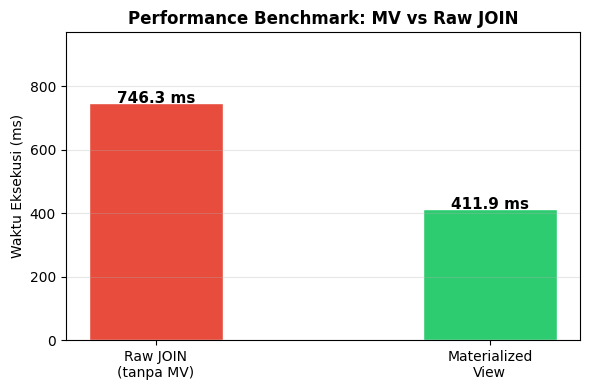

 Grafik benchmark tersimpan


In [ ]:
# Visualisasi benchmark
fig, ax = plt.subplots(figsize=(6, 4))
labels = ['Raw JOIN\n(tanpa MV)', 'Materialized\nView']
values = [t_raw * 1000, t_mv * 1000]
colors = ['#e74c3c', '#2ecc71']
bars = ax.bar(labels, values, color=colors, edgecolor='white', width=0.4)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{val:.1f} ms', ha='center', fontsize=11, fontweight='bold')
ax.set_title('Performance Benchmark: MV vs Raw JOIN', fontsize=12, fontweight='bold')
ax.set_ylabel('Waktu Eksekusi (ms)')
ax.set_ylim(0, max(values) * 1.3)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('Data/benchmark_mv_vs_raw.png', dpi=150)
plt.show()
print(' Grafik benchmark tersimpan')

---
## STEP 10 – Atoti DataMart & OLAP Cube

In [ ]:
import atoti as at
import shutil, os

# ── Tutup session lama jika masih ada ────────────────────────────────────────
try:
    session.close()
    print('   Session lama berhasil ditutup')
except Exception:
    pass  # session belum ada, lanjut

# ── Hapus folder atoti_content agar file H2 lock tidak menghalangi ───────────
# (file content.mv.db bisa ter-lock jika session sebelumnya crash / tidak ditutup)
CONTENT_DIR = './atoti_content'
if os.path.exists(CONTENT_DIR):
    shutil.rmtree(CONTENT_DIR)
    print(f'   Folder {CONTENT_DIR} dibersihkan')

# ── Start session baru ────────────────────────────────────────────────────────
session = at.Session.start(
    at.SessionConfig(
        user_content_storage=CONTENT_DIR,
        port=9090,
        java_options=['-Xms768m', '-Xmx1G']
    )
)

print('\u2705 Atoti Session berhasil dibuat')
print(f'   URL Dashboard : {session.url}')
print('   Buka URL di browser untuk dashboard interaktif')


Welcome to Atoti 0.9.14!

By using this community edition, you agree with the license available at https://docs.activeviam.com/products/atoti/python-sdk/latest/eula.html.
Browse the official documentation at https://docs.activeviam.com/products/atoti/python-sdk.
Join the community at https://www.atoti.io/register.

Atoti collects telemetry data, which is used to help understand how to improve the product.
If you don't wish to send usage data, you can request a trial license at https://www.atoti.io/evaluation-license-request.

You can hide this message by setting the `ATOTI_HIDE_EULA_MESSAGE` environment variable to True.
   Folder ./atoti_content dibersihkan
✅ Atoti Session berhasil dibuat
   URL Dashboard : http://localhost:9090
   Buka URL di browser untuk dashboard interaktif


---
## 📦 STEP 11 — Load Tabel ke Atoti

In [ ]:
# ─── STEP 11: Load Tabel ke Atoti ───────────────────────────────────────────

# Bersihkan tabel lama jika session sudah pernah dijalankan
def _drop_table_if_exists(session, table_name):
    if table_name in session.tables:
        del session.tables[table_name]

for tbl_name in ['fact_economy', 'dim_country', 'dim_time', 'dim_indicator']:
    _drop_table_if_exists(session, tbl_name)

# dim_country  → key: country_sk
tbl_country = session.read_pandas(
    dim_country,
    table_name='dim_country',
    keys=['country_sk']
)

# dim_time → key: time_id DAN year agar 'year' muncul sebagai level
tbl_time = session.read_pandas(
    dim_time,
    table_name='dim_time',
    keys=['time_id', 'year']
)

# dim_indicator → key: indicator_id
tbl_indicator = session.read_pandas(
    dim_indicator,
    table_name='dim_indicator',
    keys=['indicator_id']
)

# fact_economy → key surrogate: country_sk, indicator_id, time_id, batch
tbl_fact = session.read_pandas(
    fact_economy,
    table_name='fact_economy',
    keys=['country_sk', 'indicator_id', 'time_id', 'batch']
)

print('✅ Semua tabel berhasil di-load ke Atoti')
print(f'   fact_economy  : {len(fact_economy):,} baris')
print(f'   dim_country   : {len(dim_country)} baris')
print(f'   dim_time      : {len(dim_time)} baris')
print(f'   dim_indicator : {len(dim_indicator)} baris')


✅ Semua tabel berhasil di-load ke Atoti
   fact_economy  : 13,671 baris
   dim_country   : 217 baris
   dim_time      : 9 baris
   dim_indicator : 7 baris


---
## 🔗 STEP 12 — Join Tabel (Fact ↔ Dimension)

In [ ]:
# ─── STEP 12: Join Tabel (Fact ↔ Dimension) ─────────────────────────────────

tbl_fact.join(
    tbl_country,
    tbl_fact['country_sk'] == tbl_country['country_sk']
)

tbl_fact.join(
    tbl_time,
    tbl_fact['time_id'] == tbl_time['time_id']
)

tbl_fact.join(
    tbl_indicator,
    tbl_fact['indicator_id'] == tbl_indicator['indicator_id']
)

print('✅ Join Fact ↔ Dimension selesai')
print('   fact.country_sk   → dim_country.country_sk')
print('   fact.time_id      → dim_time.time_id')
print('   fact.indicator_id → dim_indicator.indicator_id')


✅ Join Fact ↔ Dimension selesai
   fact.country_sk   → dim_country.country_sk
   fact.time_id      → dim_time.time_id
   fact.indicator_id → dim_indicator.indicator_id


In [ ]:
cube = session.create_cube(tbl_fact, name='WorldEconomyCube')

lvl  = cube.levels
meas = cube.measures

print('✅ Cube "WorldEconomyCube" berhasil dibuat')
print('\n=== Levels (Dimensi) Tersedia ===')
for l in lvl:
    print(f'   - {l}')


✅ Cube "WorldEconomyCube" berhasil dibuat

=== Levels (Dimensi) Tersedia ===
   - ('dim_country', 'country_name', 'country_name')
   - ('dim_country', 'income_group', 'income_group')
   - ('dim_country', 'region_id', 'region_id')
   - ('dim_country', 'country_id', 'country_id')
   - ('dim_country', 'region_name', 'region_name')
   - ('dim_indicator', 'indicator_code', 'indicator_code')
   - ('dim_indicator', 'indicator_name', 'indicator_name')
   - ('fact_economy', 'extracted_at', 'extracted_at')
   - ('fact_economy', 'country_sk', 'country_sk')
   - ('fact_economy', 'indicator_id', 'indicator_id')
   - ('fact_economy', 'batch', 'batch')
   - ('fact_economy', 'time_id', 'time_id')
   - ('dim_time', 'decade', 'decade')
   - ('dim_time', 'year', 'year')


In [ ]:
meas['Avg Value']   = at.agg.mean(tbl_fact['value'])
meas['Total Value'] = at.agg.sum(tbl_fact['value'])
meas['Max Value']   = at.agg.max(tbl_fact['value'])
meas['Min Value']   = at.agg.min(tbl_fact['value'])
meas['Std Dev']     = at.agg.std(tbl_fact['value'])

print('Measures berhasil didefinisikan:')
print('   Avg Value   – rata-rata nilai indikator')
print('   Total Value – total nilai indikator')
print('   Max Value   – nilai tertinggi')
print('   Min Value   – nilai terendah')
print('   Std Dev     – standar deviasi')

Measures berhasil didefinisikan:
   Avg Value   – rata-rata nilai indikator
   Total Value – total nilai indikator
   Max Value   – nilai tertinggi
   Min Value   – nilai terendah
   Std Dev     – standar deviasi


In [ ]:
print('=== Pivot Table: Rata-rata Indikator per Region per Tahun ===')
pivot = cube.query(
    meas['Avg Value'],
    levels=[
        lvl['dim_country', 'region_name', 'region_name'],
        lvl['dim_indicator', 'indicator_name', 'indicator_name'],
        lvl['dim_time', 'year', 'year']
    ]
)
pivot


=== Pivot Table: Rata-rata Indikator per Region per Tahun ===


Avg Value
region_name         indicator_name            year          
East Asia & Pacific Central Govt Debt (% GDP) 2015     45.52
                                              2016     46.68
                                              2017     48.23
                                              2018     48.95
                                              2019     50.17
...                                                      ...
Sub-Saharan Africa  Unemployment Rate (%)     2019      8.04
                                              2020      8.85
                                              2021      9.05
                                              2022      8.46
                                              2023      8.24

[439 rows x 1 columns]

In [ ]:
q1 = cube.query(
    meas['Avg Value'],
    levels=[
        lvl['dim_country', 'region_name', 'region_name'],
        lvl['dim_time', 'year', 'year']
    ],
    filter=lvl['dim_indicator', 'indicator_name', 'indicator_name'] == 'GDP (current US$)'
)
print(f'=== DRILL-DOWN: Avg GDP per Region per Tahun | {len(q1)} baris ===')
q1


=== DRILL-DOWN: Avg GDP per Region per Tahun | 63 baris ===


Avg Value
region_name         year                    
East Asia & Pacific 2015  604,115,171,882.27
                    2016  625,821,201,843.60
                    2017  667,952,547,134.65
                    2018  728,419,453,128.60
                    2019  744,264,467,372.26
...                                      ...
Sub-Saharan Africa  2019   44,313,918,879.87
                    2020   41,193,855,651.48
                    2021   46,369,864,897.04
                    2022   49,658,164,307.37
                    2023   45,802,702,979.92

[63 rows x 1 columns]

In [ ]:
q2 = cube.query(
    meas['Avg Value'],
    meas['Std Dev'],
    levels=[
        lvl['dim_country', 'income_group', 'income_group'],
        lvl['dim_time', 'decade', 'decade']
    ],
    filter=lvl['dim_indicator', 'indicator_name', 'indicator_name'] == 'Inflation (CPI %)'
)
print(f'=== ROLL-UP: Inflasi per Income Group per Dekade | {len(q2)} baris ===')
q2


=== ROLL-UP: Inflasi per Income Group per Dekade | 10 baris ===


Avg Value Std Dev
income_group        decade                  
High income         2010s       1.36    1.41
                    2020s       4.21    2.52
Low income          2010s      15.16   38.79
                    2020s      17.02   39.75
Lower middle income 2010s       5.74   16.61
                    2020s      15.29   45.79
Not classified      2010s      61.89   68.48
                    2020s      27.83     NaN
Upper middle income 2010s       4.34    7.00
                    2020s       8.81   14.37

In [ ]:
q3 = cube.query(
    meas['Avg Value'],
    levels=[
        lvl['dim_country', 'region_name', 'region_name'],
        lvl['dim_time', 'year', 'year']
    ],
    filter=lvl['dim_indicator', 'indicator_name', 'indicator_name'] == 'Inflation (CPI %)'
)
print(f'=== SLICE: Inflasi Tiap Wilayah per Tahun | {len(q3)} baris ===')
q3

=== SLICE: Inflasi Tiap Wilayah per Tahun | 63 baris ===


Avg Value
region_name         year          
East Asia & Pacific 2015      1.69
                    2016      1.57
                    2017      2.20
                    2018      2.76
                    2019      2.05
...                            ...
Sub-Saharan Africa  2019     13.04
                    2020     22.42
                    2021     16.69
                    2022     15.70
                    2023     10.56

[63 rows x 1 columns]

In [ ]:
q4 = cube.query(
    meas['Avg Value'],
    meas['Max Value'],
    meas['Min Value'],
    meas['Std Dev'],
    levels=[
        lvl['dim_country', 'region_name', 'region_name'],
        lvl['dim_time', 'year', 'year']
    ],
    filter=(
        (lvl['dim_indicator', 'indicator_name', 'indicator_name'] == 'Unemployment Rate (%)')
        & (lvl['dim_country', 'income_group', 'income_group'] == 'High income')
        & (lvl['dim_time', 'year', 'year'] >= 2019)
        & (lvl['dim_time', 'year', 'year'] <= 2023)
    )
)
print(f'=== DICE: Unemployment – High Income – 2019–2023 | {len(q4)} baris ===')
q4


=== DICE: Unemployment – High Income – 2019–2023 | 25 baris ===


Avg Value Max Value  \
region_name                                       year                       
East Asia & Pacific                               2019      5.23     11.59   
                                                  2020      6.40     13.56   
                                                  2021      5.67     12.56   
                                                  2022      5.08     11.79   
                                                  2023      4.94     11.61   
Europe & Central Asia                             2019      5.78     17.05   
                                                  2020      6.56     15.90   
                                                  2021      6.48     14.91   
                                                  2022      5.53     13.03   
                                                  2023      5.50     12.18   
Latin America & Caribbean                         2019      8.79     13.17   
                                                  2020     11.78     16.43   
                                                  2021     10.64     15.14   
                                                  2022      8.64     12.09   
                                                  2023      7.98     11.92   
Middle East, North Africa, Afghanistan & Pakistan 2019      2.67      5.64   
                                                  2020      3.66      7.66   
                                                  2021      3.11      6.62   
                                                  2022      2.81      5.59   
                                                  2023      2.43      4.01   
North America                                     2019      4.68      5.69   
                                                  2020      8.86      9.66   
                                                  2021      6.44      7.53   
                                                  2022      4.46      5.28   
                                                  2023      4.53      5.42   

                                                       Min Value Std Dev  
region_name                                       year                    
East Asia & Pacific                               2019      1.73     NaN  
                                                  2020      2.54     NaN  
                                                  2021      2.22     NaN  
                                                  2022      2.45     NaN  
                                                  2023      2.21     .85  
Europe & Central Asia                             2019      2.02     .83  
                                                  2020      2.55     NaN  
                                                  2021      2.80     NaN  
                                                  2022      2.22     NaN  
                                                  2023      2.58     NaN  
Latin America & Caribbean                         2019      3.52     NaN  
                                                  2020      4.21     NaN  
                                                  2021      4.45     NaN  
                                                  2022      4.38     NaN  
                                                  2023      3.36     NaN  
Middle East, North Africa, Afghanistan & Pakistan 2019       .10    1.75  
                                                  2020       .14    2.22  
                                                  2021       .14    2.01  
                                                  2022       .13    1.66  
                                                  2023       .13    1.33  
North America                                     2019      3.67     NaN  
                                                  2020      8.05     NaN  
                                                  2021      5.35     NaN  
                                                  2022      3.65     NaN 

In [ ]:
q5 = cube.query(
    meas['Avg Value'],
    meas['Total Value'],
    levels=[
        lvl['fact_economy', 'batch', 'batch'],
        lvl['dim_country', 'region_name', 'region_name']
    ],
    filter=lvl['dim_indicator', 'indicator_name', 'indicator_name'] == 'GDP (current US$)'
)

# Sort dari terbesar ke terkecil
q5_sorted = q5.sort_values('Avg Value', ascending=False)

print(f'=== DRILL-DOWN: GDP per Batch per Region | {len(q5)} baris ===')
q5_sorted

=== DRILL-DOWN: GDP per Batch per Region | 21 baris ===


,,Avg Value,Total Value
batch,region_name,,
batch_3,North America,9180219268827.476562,82621973419447.28125
batch_2,North America,7568975884050.636719,68120782956455.734375
batch_1,North America,6792548233596.517578,61132934102368.65625
batch_3,East Asia & Pacific,876013281195.02832,91981394525477.96875
batch_2,East Asia & Pacific,739798696471.364136,79898259218907.328125
batch_3,South Asia,658777089392.512329,11857987609065.222656
batch_1,East Asia & Pacific,632629640286.839722,68324001150978.695312
batch_2,South Asia,536172036415.104614,9651096655471.882812
batch_3,Europe & Central Asia,465273862145.138123,79096556564673.484375


In [ ]:
q6 = cube.query(
    meas['Avg Value'],
    levels=[
        lvl['dim_country', 'region_name', 'region_name'],
        lvl['dim_time', 'year', 'year']
    ],
    filter=lvl['dim_indicator', 'indicator_name', 'indicator_name'] == 'Central Govt Debt (% GDP)'
)
print(f'=== SLICE : Hutang Pemerintah (Avg) per Wilayah per Tahun | {len(q6)} baris ===')
q6

=== SLICE : Hutang Pemerintah (Avg) per Wilayah per Tahun | 61 baris ===


Avg Value
region_name         year          
East Asia & Pacific 2015     45.52
                    2016     46.68
                    2017     48.23
                    2018     48.95
                    2019     50.17
...                            ...
Sub-Saharan Africa  2019     45.68
                    2020     57.40
                    2021     59.94
                    2022     54.83
                    2023     66.80

[61 rows x 1 columns]

In [ ]:
print(' Atoti Interactive Dashboard')
print('=' * 50)
print(f'   URL : {session.url}')
print()
print('Cara pakai di browser:')
print('  1. Klik "+ New Widget"')
print('  2. Drag dimensi ke Rows/Columns:')
print('       region_name, income_group, year, decade, indicator_name, country_name')
print('  3. Drag measure ke Values:')
print('       Avg Value, Count, Max Value, Min Value, Std Dev, Total Value')
print('  4. Gunakan filter untuk Slice & Dice')
print()
print('Contoh kombinasi menarik:')
print('  Rows=region_name | Cols=year | Val=Avg Value')
print('  Filter: indicator_name = GDP (current US$)')

session

 Atoti Interactive Dashboard
   URL : http://localhost:9090

Cara pakai di browser:
  1. Klik "+ New Widget"
  2. Drag dimensi ke Rows/Columns:
       region_name, income_group, year, decade, indicator_name, country_name
  3. Drag measure ke Values:
       Avg Value, Count, Max Value, Min Value, Std Dev, Total Value
  4. Gunakan filter untuk Slice & Dice

Contoh kombinasi menarik:
  Rows=region_name | Cols=year | Val=Avg Value
  Filter: indicator_name = GDP (current US$)


In [ ]:
# session.close()
# print(' Session ditutup')

In [ ]:
# Tutup session setelah selesai pakai Atoti UI
# Uncomment jika sudah selesai:
# session.close()
# print(' Session ditutup')